# 🚢 타이타닉 데이터로 시작하는 데이터 분석 첫걸음
### pandas · matplotlib · seaborn 입문 노트북

**이 노트북은 누구를 위한 것인가요?**
파이썬 기초(변수, 리스트, `print`)는 알지만 **pandas는 처음**인 분을 위한 노트북입니다. 모르는 단어가 나오면 바로 설명이 따라옵니다.

**학습 목표**
- 엑셀 파일 같은 표 데이터를 파이썬으로 열고, 원하는 부분만 골라볼 수 있다.
- 빈 칸(결측치)을 찾아서 채울 수 있다.
- "그룹별 평균"을 구하고, 그래프로 그릴 수 있다.
- 데이터를 근거로 간단한 결론을 말할 수 있다.

**이 노트북을 관통하는 질문**
> 1912년 타이타닉호에서 **누가 살아남았을까?** 운이었을까, 아니면 규칙이 있었을까?

**진행 방식**
- 각 셀은 위에서 아래로 순서대로 실행하세요. (`Shift + Enter`)
- `✏️ 실습` 셀에는 `____` 빈칸이 있습니다. 빈칸을 채워 실행하세요.
- 막히면 💡 힌트를 펼쳐 보세요. 정답은 별도 노트북(`titanic_basic_answers.ipynb`)에 있습니다.
- 🤔 표시는 코드를 실행한 뒤 **결과를 읽고 생각해 보는** 질문입니다. 꼭 멈춰서 생각해 보세요.

| 섹션 | 내용 | 시간 |
|---|---|---|
| 0 | 준비 — 라이브러리와 데이터 불러오기 | 15분 |
| 1 | 표 들여다보기 — pandas 기초 | 40분 |
| 2 | 빈 칸 채우고 새 열 만들기 — 전처리 | 30분 |
| 3 | 그룹별로 묶어서 비교하기 — groupby | 30분 |
| 4 | 그래프 그리기 — matplotlib | 25분 |
| 5 | 더 쉽고 예쁜 그래프 — seaborn | 25분 |
| 6 | 미니 프로젝트 & AI 답변 검증 | 30분 |
| 7 | 정리 | 5분 |


---
## 0. 준비 — 라이브러리와 데이터 불러오기

### 라이브러리란?
파이썬에 기본으로 없는 기능을 **남이 만들어 둔 도구 상자**입니다. 오늘 쓸 세 가지:

| 라이브러리 | 하는 일 | 별명(관례) |
|---|---|---|
| **pandas** | 표(엑셀 같은) 데이터를 다룸 | `pd` |
| **matplotlib** | 그래프를 그림 | `plt` |
| **seaborn** | matplotlib을 더 쉽고 예쁘게 | `sns` |

`import pandas as pd`는 "pandas를 가져오고, 앞으로 `pd`라고 짧게 부르겠다"는 뜻입니다. 별명은 전 세계 사람들이 똑같이 쓰는 약속이니 그대로 따르세요.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print('준비 완료!')

준비 완료!


### 한글 폰트 설정
그래프 제목에 한글을 쓰면 `□□□`로 깨질 수 있어요. 아래 셀은 내 컴퓨터에 있는 한글 폰트를 찾아서 설정합니다.
(무슨 뜻인지 지금 다 이해하지 않아도 됩니다. 그냥 실행하세요.)
Google Colab을 쓴다면 `!apt-get install -y fonts-nanum`을 먼저 실행하고 런타임을 재시작하세요.

In [3]:
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')   # 경고 메시지 숨기기

for name in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if name in {f.name for f in fm.fontManager.ttflist}:
        plt.rcParams['font.family'] = name
        print('한글 폰트:', name)
        break
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', font=plt.rcParams['font.family'][0])

한글 폰트: Malgun Gothic


### 데이터 불러오기
`pd.read_csv('파일이름.csv')` 한 줄이면 CSV 파일(쉼표로 구분된 표)을 읽어옵니다.
읽어온 표를 **DataFrame**이라고 부르고, 보통 `df`라는 변수에 담습니다.

In [4]:
import os
if os.path.exists('EDA 기초/titanic.csv'):
    df = pd.read_csv('EDA 기초/titanic.csv')
else:   # 같은 폴더에 파일이 없으면 인터넷에서 바로 받아옵니다
    df = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')

print('불러오기 성공!')

불러오기 성공!


### 데이터셋 소개
타이타닉호 승객 891명의 정보입니다. 열(column) 하나가 정보 하나입니다.

| 열 이름 | 뜻 |
|---|---|
| `PassengerId` | 승객 번호 |
| `Survived` | 생존 여부 — **0 = 사망, 1 = 생존** ← 우리가 가장 궁금한 것 |
| `Pclass` | 객실 등급 — 1 = 1등석(비쌈), 2 = 2등석, 3 = 3등석(쌈) |
| `Name` | 이름 |
| `Sex` | 성별 (male / female) |
| `Age` | 나이 |
| `SibSp` | 같이 탄 형제자매·배우자 수 |
| `Parch` | 같이 탄 부모·자녀 수 |
| `Ticket` | 티켓 번호 |
| `Fare` | 요금 |
| `Cabin` | 객실 번호 |
| `Embarked` | 탑승 항구 — C = 셰르부르, Q = 퀸스타운, S = 사우샘프턴 |

---
## 1. 표 들여다보기 — pandas 기초

### 1-1. 처음 몇 줄 보기: `head()`
데이터를 받으면 **가장 먼저** 하는 일입니다. `df.head()`는 위에서 5줄을 보여줍니다.

In [5]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**결과 읽는 법**
- 맨 왼쪽의 굵은 숫자 `0, 1, 2, ...`는 **인덱스(행 번호)**입니다. 파이썬은 0부터 셉니다.
- 각 열 이름 아래에 값이 있습니다. `NaN`은 **"값이 없음(빈 칸)"**이라는 뜻입니다. `Cabin` 열에 많이 보이죠?

괄호 안에 숫자를 넣으면 그만큼 보여줍니다.

In [6]:
df.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [7]:
df.tail(3)    # 마지막 3줄

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


### 1-2. 크기 확인: `shape`
`shape`는 **(행 수, 열 수)**를 알려줍니다. 뒤에 괄호가 **없다**는 점에 주의하세요 — 함수가 아니라 속성(정보)이기 때문입니다.

In [8]:
df.shape

(891, 12)

> 🤔 행이 891개, 열이 12개입니다. 즉 승객 891명, 정보 12가지.

### 1-3. 전체 요약: `info()`
각 열에 **빈 칸이 없는 값이 몇 개인지(Non-Null Count)**와 **자료형(Dtype)**을 보여줍니다.

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


**결과 읽는 법**
- 전체가 891행인데 `Age`는 714개만 있다 → **177개가 빈 칸**
- `Cabin`은 204개만 있다 → 687개가 빈 칸 (거의 다 비어 있음!)
- Dtype: `int64` = 정수, `float64` = 소수, `object` = 글자(문자열)

> 🤔 `Embarked`는 몇 개가 비어 있나요?

### 1-4. 숫자 요약: `describe()`
숫자 열마다 개수·평균·최소·최대 등을 한 번에 보여줍니다.

In [10]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**결과 읽는 법** (각 행의 뜻)

| 행 | 뜻 |
|---|---|
| count | 빈 칸이 아닌 값의 개수 |
| mean | 평균 |
| std | 표준편차 (값들이 얼마나 흩어져 있나) |
| min / max | 최솟값 / 최댓값 |
| 25% / 50% / 75% | 값을 작은 순으로 줄 세웠을 때 25%, 50%(=중앙값), 75% 지점 |

> 🤔 `Survived`의 mean이 0.38입니다. 0과 1의 평균이 0.38이라는 건, **전체의 38%가 생존**했다는 뜻이에요.
> 🤔 `Age`의 max는 80, `Fare`의 max는 512입니다. 512달러를 낸 사람은 누굴까요? (나중에 찾아봅니다)

### 1-5. 열 하나 꺼내기: `df['열이름']`
대괄호 안에 열 이름을 **따옴표와 함께** 넣습니다. 열 하나를 꺼낸 것을 **Series**라고 부릅니다.

In [11]:
df['Age']

0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888     NaN
889    26.0
890    32.0
Name: Age, Length: 891, dtype: float64

In [12]:
# Series에 바로 계산을 붙일 수 있습니다
print('평균 나이:', df['Age'].mean())
print('최고령  :', df['Age'].max())
print('최연소  :', df['Age'].min())

평균 나이: 29.69911764705882
최고령  : 80.0
최연소  : 0.42


In [13]:
df['Pclass']

0      3
1      1
2      3
3      1
4      3
      ..
886    2
887    1
888    3
889    1
890    3
Name: Pclass, Length: 891, dtype: int64

### 1-6. 열 여러 개 꺼내기: `df[['열1', '열2']]`
대괄호가 **두 겹**입니다. 안쪽 대괄호는 "열 이름 리스트"입니다.

In [14]:
df[['Name', 'Age', 'Survived']].head()

,Name,Age,Survived
0,"Braund, Mr. Owen Harris",22.0,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1
2,"Heikkinen, Miss. Laina",26.0,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1
4,"Allen, Mr. William Henry",35.0,0


### 1-7. 값 개수 세기: `value_counts()`
글자로 된 열(성별, 항구 등)에서 **각 값이 몇 번 나오는지** 셉니다. 매우 자주 씁니다.

In [15]:
df['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [16]:
df['Pclass'].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [17]:
# normalize=True 를 붙이면 개수 대신 비율
df['Embarked'].value_counts(normalize=True)

Embarked
S    0.724409
C    0.188976
Q    0.086614
Name: proportion, dtype: float64

> 🤔 남성이 577명, 여성이 314명. 3등석이 제일 많습니다. 탑승객의 72%가 S(사우샘프턴)에서 탔네요.

### ✏️ 실습 1-A. 기본 탐색

빈칸을 채워서 (1) 요금(`Fare`)의 평균, (2) 탑승 항구(`Embarked`)별 승객 수를 출력하세요.

<details>
<summary>💡 힌트 (클릭해서 펼치기)</summary>

(1) `df['Fare'].mean()`  (2) `df['Embarked'].value_counts()`

</details>

In [18]:
# (1) 요금 평균
print('평균 요금:', df['Fare'].mean())

# (2) 항구별 승객 수
df['Embarked'].value_counts()

평균 요금: 32.204207968574636


Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

### 1-8. 조건으로 행 고르기 (필터링) — ⭐ 가장 중요

"여성 승객만 보고 싶다"처럼 **조건에 맞는 행만** 골라내는 방법입니다. 두 단계로 이해하세요.

**1단계** — 조건식은 각 행이 조건에 맞는지 **True / False**로 알려줍니다.

In [19]:
df['Sex'] == 'female'

0      False
1       True
2       True
3       True
4      False
       ...  
886    False
887     True
888     True
889    False
890    False
Name: Sex, Length: 891, dtype: bool

**2단계** — 그 True/False를 `df[ ]` 안에 넣으면 **True인 행만** 남습니다.

In [20]:
women = df[df['Sex'] == 'female']
women.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [21]:
print('여성 승객 수:', len(women))          # len() = 행 개수
print('여성 생존율:', women['Survived'].mean())

여성 승객 수: 314
여성 생존율: 0.7420382165605095


> 🤔 여성 생존율이 **74%**! 전체 평균(38%)의 두 배입니다. 벌써 첫 번째 규칙을 찾았네요.

**숫자 조건도 똑같습니다.** `<`, `>`, `<=`, `>=`, `==`, `!=` 모두 가능.

In [22]:
children = df[df['Age'] < 13]
print('13세 미만 어린이 수:', len(children))
print('어린이 생존율:', children['Survived'].mean())

13세 미만 어린이 수: 69
어린이 생존율: 0.5797101449275363


### 1-9. 조건 두 개 합치기: `&`(그리고), `|`(또는)
"여성 **이면서** 1등석" 같은 경우입니다. **규칙 두 가지**를 꼭 지키세요.
1. `and` / `or`가 아니라 **`&` / `|`**를 씁니다.
2. 각 조건을 **괄호**로 감쌉니다.

```python
df[ (조건1) & (조건2) ]
```

In [23]:
first_women = df[(df['Sex'] == 'female') & (df['Pclass'] == 1)]
print('1등석 여성 수:', len(first_women))
print('1등석 여성 생존율:', first_women['Survived'].mean())

1등석 여성 수: 94
1등석 여성 생존율: 0.9680851063829787


> 🤔 1등석 여성의 생존율은 **97%**입니다. 거의 다 살았네요.

### ✏️ 실습 1-B. 3등석 남성의 생존율은?

`Pclass`가 3이고 `Sex`가 'male'인 승객을 골라서, 몇 명인지와 생존율을 출력하세요.

<details>
<summary>💡 힌트 (클릭해서 펼치기)</summary>

`df[(df['Pclass'] == 3) & (df['Sex'] == 'male')]` — 괄호와 `&`를 잊지 마세요. 생존율은 `['Survived'].mean()`.

</details>

In [24]:
third_men = df[(df['Pclass'] == 3) & (df['Sex'] == 'male')]

print('3등석 남성 수:', len(third_men))
print('3등석 남성 생존율:', third_men['Survived'].mean())

3등석 남성 수: 347
3등석 남성 생존율: 0.13544668587896252


### 1-10. 빈 칸(결측치) 찾기: `isnull().sum()`
`isnull()`은 빈 칸이면 True, 아니면 False. 거기에 `.sum()`을 붙이면 True 개수(= 빈 칸 개수)를 셉니다.

In [25]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

> 🤔 `Age` 177개, `Cabin` 687개, `Embarked` 2개가 비어 있습니다. 이걸 어떻게 처리할지가 다음 섹션 주제입니다.

### ✏️ 실습 1-C. 나이를 모르는 승객은 더 많이 죽었을까?

`df['Age'].isnull()`은 나이가 빈 칸인 행에서 True입니다. 이걸 조건으로 써서 **나이가 빈 칸인 승객의 생존율**을 구하세요. 그리고 전체 생존율(0.38)과 비교해 보세요.

<details>
<summary>💡 힌트 (클릭해서 펼치기)</summary>

`df[df['Age'].isnull()]`로 행을 고른 뒤 `['Survived'].mean()`.

</details>

In [26]:
no_age = df[df['Age'].isnull()]
print('나이 미상 승객 수:', len(no_age))
print('나이 미상 승객 생존율:', no_age['Survived'].mean())

나이 미상 승객 수: 177
나이 미상 승객 생존율: 0.2937853107344633


---
## 2. 빈 칸 채우고 새 열 만들기 — 전처리

실제 데이터는 항상 지저분합니다. 분석 전에 정리하는 과정을 **전처리**라고 합니다.

### 2-1. 원본은 건드리지 않기: `copy()`
실수로 망쳐도 돌아갈 수 있게, **복사본**을 만들어 거기서 작업합니다.

In [27]:
data = df.copy()     # 앞으로는 data를 씁니다. df는 원본 그대로 보관.

### 2-2. 빈 칸 채우기: `fillna()`
빈 칸을 그대로 두면 평균 계산이나 그래프에서 문제가 생깁니다. 열마다 다르게 처리합니다.

| 열 | 빈 칸 수 | 처리 방법 | 이유 |
|---|---|---|---|
| `Age` | 177 | **중앙값**으로 채움 | 평균은 극단값에 끌려가지만 중앙값은 안정적 |
| `Embarked` | 2 | **가장 많은 값**(S)으로 채움 | 2명뿐이라 무엇으로 채워도 큰 영향 없음 |
| `Cabin` | 687 | 열 자체를 **삭제** | 77%가 비어 있어 복구 불가 |

> **중앙값(median)**: 값을 줄 세웠을 때 딱 가운데 값. 예를 들어 `[1, 2, 3, 100]`의 평균은 26.5지만 중앙값은 2.5입니다.

In [28]:
# Age: 중앙값으로
age_median = data['Age'].median()
print('나이 중앙값:', age_median)
data['Age'] = data['Age'].fillna(age_median)

나이 중앙값: 28.0


In [29]:
# Embarked: 가장 많은 값으로. mode()는 최빈값을 돌려주는데, 여러 개일 수 있어서 [0]으로 첫 번째를 꺼냅니다.
most_common = data['Embarked'].mode()[0]
print('가장 많은 항구:', most_common)
data['Embarked'] = data['Embarked'].fillna(most_common)

가장 많은 항구: S


In [30]:
# Cabin: 열 삭제
data = data.drop(columns=['Cabin'])

In [31]:
# 확인 — 빈 칸이 다 사라졌나요?
data.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

> 🤔 `Age`를 모두 28세로 채웠습니다. 그런데 이름에 'Master'(어린 남자아이 호칭)가 붙은 승객도 28세가 되었겠죠? 이게 완벽한 방법은 아니라는 뜻입니다. 지금은 단순하게 가고, 더 나은 방법은 다음 단계에서 배웁니다.

### 2-3. 새 열 만들기 (파생 변수)
기존 열을 계산해서 **더 쓸모 있는 열**을 만듭니다. `data['새이름'] = 계산식` 형태입니다.

예: 형제자매·배우자(`SibSp`) + 부모·자녀(`Parch`) + 본인 1명 = **가족 수**

In [32]:
data['FamilySize'] = data['SibSp'] + data['Parch'] + 1
data[['Name', 'SibSp', 'Parch', 'FamilySize']].head()

,Name,SibSp,Parch,FamilySize
0,"Braund, Mr. Owen Harris",1,0,2
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,0,2
2,"Heikkinen, Miss. Laina",0,0,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,0,2
4,"Allen, Mr. William Henry",0,0,1


조건식의 결과(True/False)를 숫자(1/0)로 바꿔서 열로 만들 수도 있습니다. `astype(int)`가 그 역할입니다.

In [33]:
data['IsAlone'] = (data['FamilySize'] == 1).astype(int)    # 혼자면 1, 아니면 0
data['IsAlone'].value_counts()

IsAlone
1    537
0    354
Name: count, dtype: int64

### 2-4. 숫자를 구간으로 나누기: `pd.cut()`
나이를 "어린이 / 청소년 / 성인 / 노년"처럼 묶으면 비교가 쉬워집니다.
- `bins`: 경계값 리스트. `[0, 12, 18, 60, 100]`이면 0~12, 12~18, 18~60, 60~100 네 구간
- `labels`: 각 구간의 이름 (경계값보다 하나 적어야 함)

In [34]:
data['AgeGroup'] = pd.cut(data['Age'],
                          bins=[0, 12, 18, 60, 100],
                          labels=['어린이', '청소년', '성인', '노년'])
data['AgeGroup'].value_counts()

AgeGroup
성인     730
청소년     70
어린이     69
노년      22
Name: count, dtype: int64

### 2-5. 글자 다루기: 이름에서 호칭 꺼내기
`Name` 열을 보면 `"Braund, Mr. Owen Harris"` 형식입니다. 쉼표 뒤에 **호칭(Mr, Mrs, Miss, Master)**이 있죠.
호칭은 성별·나이·결혼 여부를 동시에 알려줘서 쓸모가 많습니다.

글자를 자를 때는 `.str.split('기준')`을 씁니다. 한 단계씩 보겠습니다.

In [35]:
name = data['Name'][0]
print('원래 이름 :', name)
print('쉼표로 자름:', name.split(', '))          # ['Braund', 'Mr. Owen Harris']
print('뒷부분    :', name.split(', ')[1])       # 'Mr. Owen Harris'
print('마침표로 자름:', name.split(', ')[1].split('.'))   # ['Mr', ' Owen Harris']
print('호칭      :', name.split(', ')[1].split('.')[0])  # 'Mr'

원래 이름 : Braund, Mr. Owen Harris
쉼표로 자름: ['Braund', 'Mr. Owen Harris']
뒷부분    : Mr. Owen Harris
마침표로 자름: ['Mr', ' Owen Harris']
호칭      : Mr


위 과정을 **열 전체**에 한 번에 적용하려면 앞에 `.str`을 붙입니다.

In [36]:
data['Title'] = data['Name'].str.split(', ').str[1].str.split('.').str[0]
data['Title'].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

Mr, Miss, Mrs, Master 네 가지가 대부분이고 나머지는 드뭅니다. 드문 것은 'Rare'로 묶어 정리합니다.
`isin([리스트])`는 "값이 이 리스트 안에 있나?"를 True/False로 알려줍니다.

In [37]:
main_titles = ['Mr', 'Miss', 'Mrs', 'Master']
is_main = data['Title'].isin(main_titles)
data.loc[~is_main, 'Title'] = 'Rare'      # ~ 는 "반대(not)". 즉 주요 호칭이 아닌 행의 Title을 'Rare'로
data['Title'].value_counts()

Title
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64

> 💬 `data.loc[조건, '열']`은 "조건에 맞는 행의 그 열"을 가리킵니다. 여기에 `= 값`을 하면 그 자리만 바뀝니다. 지금은 "이렇게 쓰는구나" 정도로만 알아두세요.

### ✏️ 실습 2-A. 어린이 표시 열 만들기

`Age`가 13 미만이면 1, 아니면 0인 `IsChild` 열을 만들고, 어린이가 몇 명인지 확인하세요.

<details>
<summary>💡 힌트 (클릭해서 펼치기)</summary>

2-3의 `IsAlone` 만든 방법과 똑같습니다. `(data['Age'] < 13).astype(int)`

</details>

In [38]:
data['IsChild'] = (data['Age'] < 13).astype(int)
data['IsChild'].value_counts()

IsChild
0    822
1     69
Name: count, dtype: int64

### ✏️ 실습 2-B. 요금 구간 만들기

`pd.cut`으로 `Fare`를 네 구간으로 나눈 `FareGroup` 열을 만드세요. 경계는 `[0, 10, 30, 100, 600]`, 이름은 `['저가', '중저가', '중고가', '고가']`로 합니다. 그리고 구간별 승객 수를 확인하세요. (요금 0원인 승객이 있으니 `include_lowest=True`를 추가하면 0도 포함됩니다.)

<details>
<summary>💡 힌트 (클릭해서 펼치기)</summary>

2-4의 `AgeGroup` 코드를 그대로 따라 하세요. `pd.cut(data['Fare'], bins=[...], labels=[...], include_lowest=True)`

</details>

In [39]:
data['FareGroup'] = pd.cut(data['Fare'],
                           bins=[0, 10, 30, 100, 600],
                           labels=['저가', '중저가', '중고가', '고가'],
                           include_lowest=True)
data['FareGroup'].value_counts()

FareGroup
저가     336
중저가    321
중고가    181
고가      53
Name: count, dtype: int64

---
## 3. 그룹별로 묶어서 비교하기 — groupby**

"성별 생존율"처럼 **그룹마다 통계**를 구하는 것이 데이터 분석의 핵심입니다. 1단계에서는 필터링으로 하나씩 구했지만, `groupby`를 쓰면 **한 줄로 모든 그룹**을 구합니다.

### 3-1. `groupby('기준열')['계산할열'].함수()`
읽는 법: "`Sex`로 묶어서(groupby), `Survived`의(['Survived']) 평균(mean)을 구해라" 

In [40]:
data.groupby('Sex')['Survived'].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

1-8에서 필터링으로 구한 여성 생존율 0.74가 그대로 나오고, 남성 0.19도 한 번에 나왔습니다.

In [41]:
data.groupby('Pclass')['Survived'].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

> 🤔 1등석 63%, 2등석 47%, 3등석 24%. 등급이 높을수록 많이 살았습니다.

함수를 바꾸면 다른 통계가 나옵니다: `mean`(평균), `sum`(합), `count`(개수), `max`, `min`, `median`

In [42]:
print(data.groupby('Pclass')['Fare'].mean())     # 등급별 평균 요금
print()
print(data.groupby('Pclass')['Survived'].sum())   # 등급별 생존자 수 (1을 더하니까)

Pclass
1    84.154687
2    20.662183
3    13.675550
Name: Fare, dtype: float64

Pclass
1    136
2     87
3    119
Name: Survived, dtype: int64


### 3-2. 여러 통계를 한 번에: `agg([...])`
`mean`, `count`를 나란히 보고 싶으면 `agg`에 리스트로 넣습니다. **생존율 옆에 인원수를 같이 보는 습관**이 중요합니다 — 3명 중 3명 생존(100%)과 300명 중 300명 생존은 다르니까요.

In [43]:
data.groupby('AgeGroup')['Survived'].agg(['mean', 'count'])

,mean,count
AgeGroup,,
어린이,0.579710,69
청소년,0.428571,70
성인,0.365753,730
노년,0.227273,22


> 🤔 어린이 생존율 58%, 청소년 43%, 성인 36%, 노년 27%. 노년 그룹은 22명뿐이니 해석에 주의하세요.

### 3-3. 두 개 기준으로 묶기
`groupby`에 리스트를 넣으면 "성별 **그리고** 등급별"로 묶입니다.

In [44]:
data.groupby(['Sex', 'Pclass'])['Survived'].mean()

Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64

### 3-4. 표 모양으로 보기: `pivot_table`
위 결과를 **행 = 성별, 열 = 등급**인 표로 펼치면 훨씬 읽기 쉽습니다. 엑셀의 피벗 테이블과 같습니다.

- `index`: 행에 올 열
- `columns`: 열에 올 열
- `values`: 계산할 열
- `aggfunc`: 계산 방법 (`'mean'`, `'count'` 등)

In [45]:
pd.pivot_table(data, index='Sex', columns='Pclass', values='Survived', aggfunc='mean')

Pclass,1,2,3
Sex,,,
female,0.968085,0.921053,0.500000
male,0.368852,0.157407,0.135447


> 🤔 1등석 여성 97% → 3등석 남성 14%. 여성은 3등석이어도 50%인데, 남성은 1등석이어도 37%입니다. **성별의 영향이 등급보다 큽니다.**

`.round(2)`를 붙이면 소수점 둘째 자리까지만 보여줍니다.

In [46]:
pd.pivot_table(data, index='Sex', columns='Pclass', values='Survived', aggfunc='mean').round(2)

Pclass,1,2,3
Sex,,,
female,0.97,0.92,0.50
male,0.37,0.16,0.14


### 3-5. 개수 세기 표: `crosstab`
두 열의 **조합별 개수**를 셀 때는 `pd.crosstab(행, 열)`이 가장 간단합니다.

In [47]:
pd.crosstab(data['Pclass'], data['Survived'])

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


> 🤔 3등석은 491명 중 372명이 사망했습니다. `normalize='index'`를 붙이면 행마다 비율로 바뀝니다.

In [48]:
pd.crosstab(data['Pclass'], data['Survived'], normalize='index').round(2)

Survived,0,1
Pclass,,
1,0.37,0.63
2,0.53,0.47
3,0.76,0.24


### ✏️ 실습 3-A. 탑승 항구별 생존율

`groupby`로 `Embarked`별 생존율과 인원수를 함께 구하세요.

<details>
<summary>💡 힌트 (클릭해서 펼치기)</summary>

3-2 코드에서 `AgeGroup`을 `Embarked`로 바꾸면 됩니다.

</details>

In [49]:
data.groupby('Embarked')['Survived'].agg(생존율 = 'mean', 인원수 = 'count')

,생존율,인원수
Embarked,,
C,0.553571,168
Q,0.389610,77
S,0.339009,646


### ✏️ 실습 3-B. 호칭별 생존율 표

`pivot_table`로 행 = `Title`, 열 = `Pclass`, 값 = 생존율 표를 만드세요. 소수점 둘째 자리까지.

<details>
<summary>💡 힌트 (클릭해서 펼치기)</summary>

3-4 코드에서 `index='Sex'`를 `index='Title'`로 바꾸세요.

</details>

In [50]:
pd.pivot_table(data, index='Title', columns='Pclass', values='Survived', aggfunc='mean').round(2)

Pclass,1,2,3
Title,,,
Master,1.00,1.00,0.39
Miss,0.96,0.94,0.50
Mr,0.35,0.09,0.11
Mrs,0.98,0.90,0.50
Rare,0.61,0.11,NaN


### ✏️ 실습 3-C. 혼자 탄 사람 vs 가족과 탄 사람

`crosstab`으로 `IsAlone`(행)과 `Survived`(열)의 비율표를 만드세요.

<details>
<summary>💡 힌트 (클릭해서 펼치기)</summary>

3-5의 마지막 코드에서 `Pclass`를 `IsAlone`으로 바꾸세요.

</details>

In [51]:
pd.crosstab(data['IsAlone'], data['Survived'], normalize='index').round(2)

Survived,0,1
IsAlone,,
0,0.49,0.51
1,0.70,0.30


---
## 4. 그래프 그리기 — matplotlib

숫자 표도 좋지만, **그림이 훨씬 빨리 이해됩니다.** matplotlib 그래프는 늘 같은 틀입니다:

```python
plt.figure(figsize=(가로, 세로))   # 도화지 준비
plt.그래프종류(데이터)              # 그리기
plt.title('제목')                  # 꾸미기
plt.xlabel('x축 이름')
plt.ylabel('y축 이름')
plt.show()                         # 보여주기
```

### 4-1. 막대 그래프: `plt.bar(x, 높이)`
범주(등급, 성별 등)별 **크기 비교**에 씁니다.

Pclass
1    216
2    184
3    491
Name: count, dtype: int64


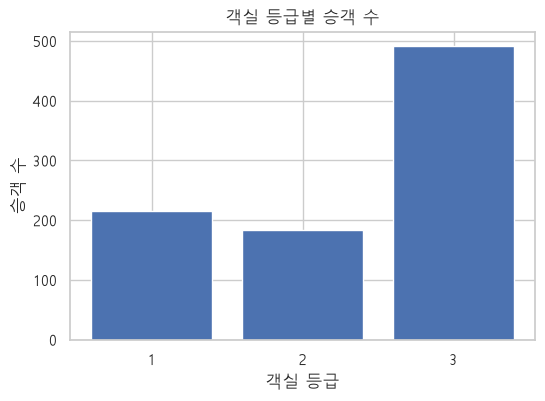

In [52]:
counts = data['Pclass'].value_counts().sort_index()   # sort_index: 1,2,3 순서로 정렬
print(counts)

plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values)
plt.title('객실 등급별 승객 수')
plt.xlabel('객실 등급')
plt.ylabel('승객 수')
plt.xticks([1, 2, 3])     # x축 눈금을 1, 2, 3만 표시
plt.show()

`counts.index`는 막대의 위치(1, 2, 3), `counts.values`는 막대의 높이(216, 184, 491)입니다.

**groupby 결과도 바로 그릴 수 있습니다.**

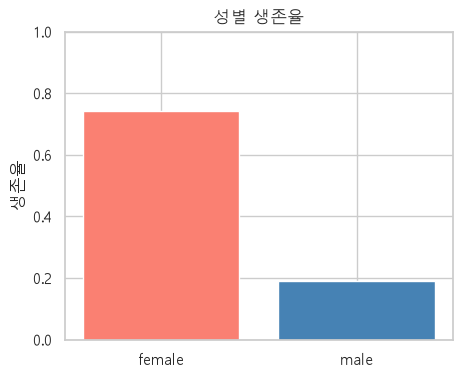

In [53]:
rate = data.groupby('Sex')['Survived'].mean()

plt.figure(figsize=(5, 4))
plt.bar(rate.index, rate.values, color=['salmon', 'steelblue'])
plt.title('성별 생존율')
plt.ylabel('생존율')
plt.ylim(0, 1)            # y축 범위를 0~1로 고정 (비율이니까)
plt.show()

### 4-2. 히스토그램: `plt.hist(데이터, bins=구간수)`
**숫자 값이 어떻게 퍼져 있는지(분포)**를 봅니다. 나이가 몇 살대에 많은지 같은 것.

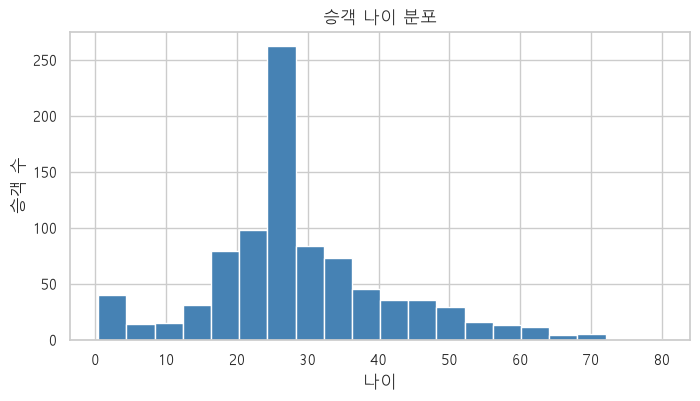

In [54]:
plt.figure(figsize=(8, 4))
plt.hist(data['Age'], bins=20, color='steelblue', edgecolor='white')
plt.title('승객 나이 분포')
plt.xlabel('나이')
plt.ylabel('승객 수')
plt.show()

> 🤔 20~30대가 가장 많습니다. 28세 막대가 유난히 높은 이유는? (2-2에서 빈 칸 177개를 28로 채웠기 때문입니다! 전처리가 그래프에 흔적을 남깁니다.)

### 4-3. 산점도: `plt.scatter(x, y)`
**숫자 두 개의 관계**를 봅니다. 점 하나가 승객 한 명입니다.

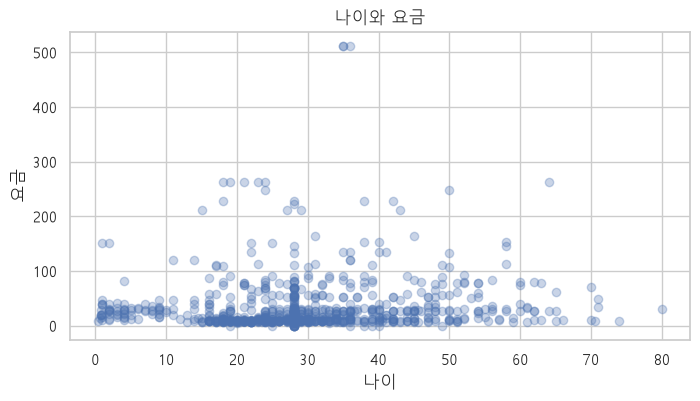

In [55]:
plt.figure(figsize=(8, 4))
plt.scatter(data['Age'], data['Fare'], alpha=0.3)    # alpha: 투명도 (겹치는 점 보이게)
plt.title('나이와 요금')
plt.xlabel('나이')
plt.ylabel('요금')
plt.show()

> 🤔 나이와 요금 사이에 뚜렷한 관계가 보이나요? (안 보입니다. 그것도 중요한 발견입니다.) 위에 홀로 떨어진 512달러 점 3개가 보이죠?

### 4-4. 박스플롯: `plt.boxplot(데이터)`
분포를 **상자 하나로 요약**합니다. 상자 = 가운데 50%, 상자 속 선 = 중앙값, 바깥 동그라미 = 유난히 큰/작은 값(이상치).

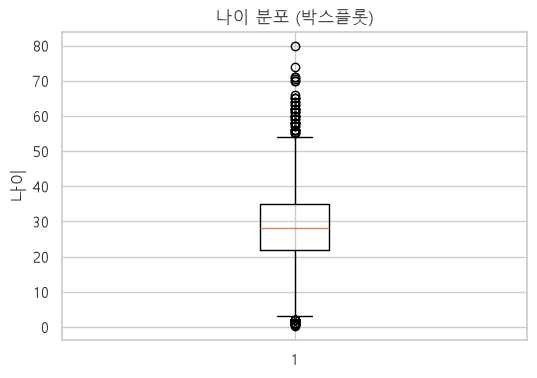

In [56]:
plt.figure(figsize=(6, 4))
plt.boxplot(data['Age'])
plt.title('나이 분포 (박스플롯)')
plt.ylabel('나이')
plt.show()

### 4-5. 그래프 두 개 겹치기
`plt.show()` 전에 그리기 명령을 여러 번 쓰면 **한 도화지에 겹쳐** 그려집니다. `label`을 달고 `plt.legend()`를 부르면 범례가 생깁니다.

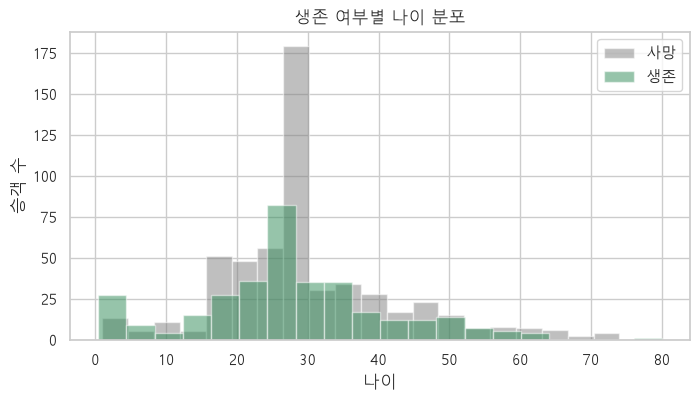

In [57]:
survived = data[data['Survived'] == 1]
died     = data[data['Survived'] == 0]

plt.figure(figsize=(8, 4))
plt.hist(died['Age'],     bins=20, alpha=0.5, label='사망', color='gray')
plt.hist(survived['Age'], bins=20, alpha=0.5, label='생존', color='seagreen')
plt.title('생존 여부별 나이 분포')
plt.xlabel('나이')
plt.ylabel('승객 수')
plt.legend()
plt.show()

> 🤔 왼쪽 끝(0~10세)에서는 초록(생존)이 회색(사망)과 비슷하거나 더 높지만, 20~30대에서는 회색이 압도적입니다.

### ✏️ 실습 4-A. 객실 등급별 생존율 막대 그래프

`groupby`로 등급별 생존율을 구한 뒤 막대 그래프로 그리세요. 제목과 축 이름을 붙이고, y축은 0~1로 고정하세요.

<details>
<summary>💡 힌트 (클릭해서 펼치기)</summary>

4-1의 두 번째 코드에서 `'Sex'`를 `'Pclass'`로 바꾸고, `plt.xticks([1, 2, 3])`을 추가하세요.

</details>

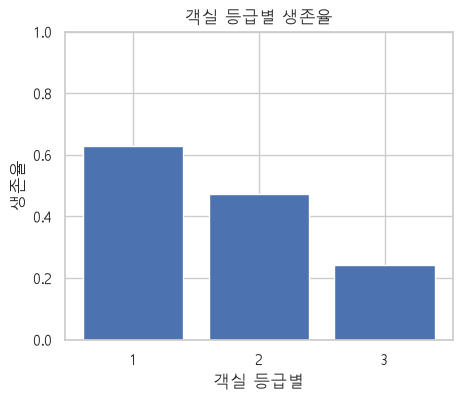

In [58]:
rate = data.groupby('Pclass')['Survived'].mean()

plt.figure(figsize=(5, 4))
plt.bar(rate.index, rate.values)
plt.title('객실 등급별 생존율')
plt.xlabel('객실 등급별')
plt.ylabel('생존율')
plt.ylim(0, 1)
plt.xticks([1, 2, 3])
plt.show()

### ✏️ 실습 4-B. 생존 여부별 요금 히스토그램 겹치기

4-5 코드를 참고해, `Fare`에 대해 사망/생존 히스토그램을 겹쳐 그리세요. 요금은 대부분 100 이하이므로 `plt.xlim(0, 150)`으로 x축을 잘라서 보세요.

<details>
<summary>💡 힌트 (클릭해서 펼치기)</summary>

4-5 코드에서 `'Age'`를 `'Fare'`로 바꾸고 `plt.xlim(0, 150)`을 추가하세요. `bins`는 50 정도가 적당합니다.

</details>

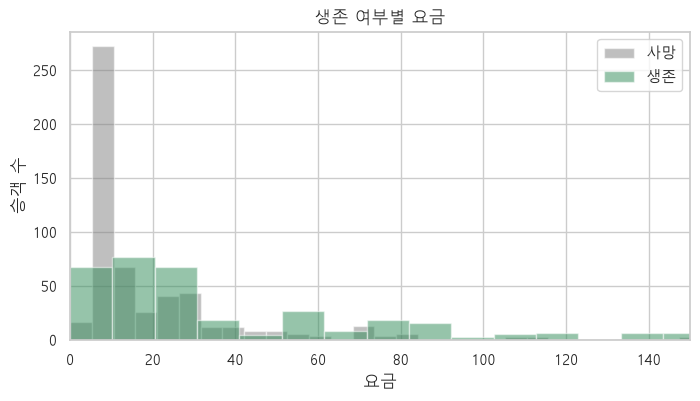

In [59]:
plt.figure(figsize=(8, 4))
plt.hist(died['Fare'],     bins=50, alpha=0.5, label='사망', color='gray')
plt.hist(survived['Fare'], bins=50, alpha=0.5, label='생존', color='seagreen')
plt.title('생존 여부별 요금')
plt.xlabel('요금')
plt.ylabel('승객 수')
plt.xlim(0, 150)
plt.legend()
plt.show()

---
## 5. 더 쉽고 예쁜 그래프 — seaborn

seaborn은 **DataFrame과 열 이름만 넘기면** 알아서 그려줍니다. 기본 형태:

```python
sns.그래프종류(data=data, x='열이름', y='열이름')
plt.show()
```

특히 **`hue='열이름'`** 하나를 추가하면 그 열의 값별로 **색을 나눠** 그려줍니다. 이게 seaborn의 가장 큰 장점입니다.

### 5-1. 개수 막대: `countplot`
`value_counts` + `plt.bar`를 한 줄로.

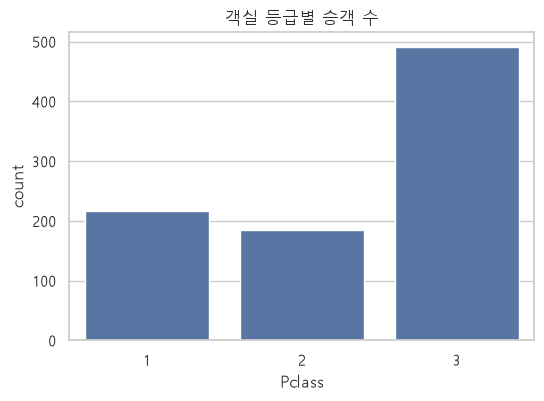

In [60]:
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x='Pclass')
plt.title('객실 등급별 승객 수')
plt.show()

여기에 `hue='Survived'`를 더하면 등급마다 사망/생존이 나란히 그려집니다.

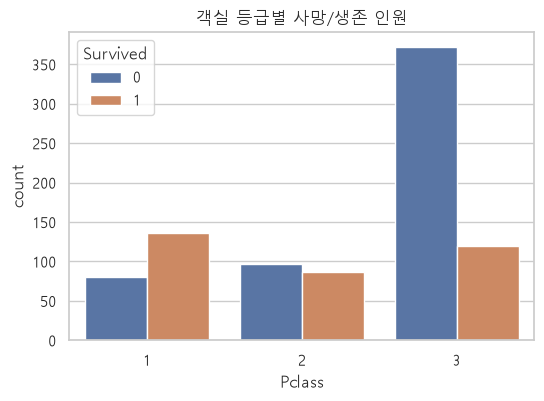

In [61]:
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x='Pclass', hue='Survived')
plt.title('객실 등급별 사망/생존 인원')
plt.show()

> 🤔 3등석의 사망(0) 막대가 압도적으로 높습니다. 1등석은 생존이 더 많습니다.

### 5-2. 평균 막대: `barplot`
`y`에 넣은 열의 **평균**을 그립니다. `y='Survived'`면 생존율이 됩니다. 막대 위의 검은 선은 **"이 평균이 얼마나 믿을 만한가"**를 나타내는 오차 범위 — 길수록 데이터가 적어 불확실하다는 뜻입니다.

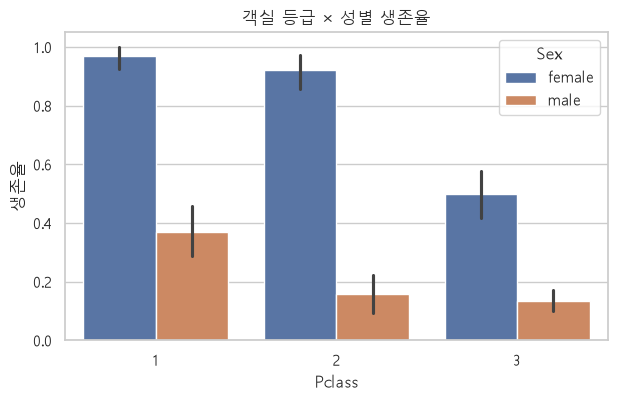

In [62]:
plt.figure(figsize=(7, 4))
sns.barplot(data=data, x='Pclass', y='Survived', hue='Sex')
plt.title('객실 등급 × 성별 생존율')
plt.ylabel('생존율')
plt.show()

> 🤔 3-4의 피벗 테이블을 그림으로 그린 것입니다. 3등석 여성의 검은 선이 1등석 여성보다 긴 이유는? (3등석 여성은 생존율이 50% 근처라 흩어짐이 크기 때문입니다.)

### 5-3. 분포 상자: `boxplot`
`x`에 범주, `y`에 숫자를 넣으면 범주별 박스플롯이 나란히 그려집니다.

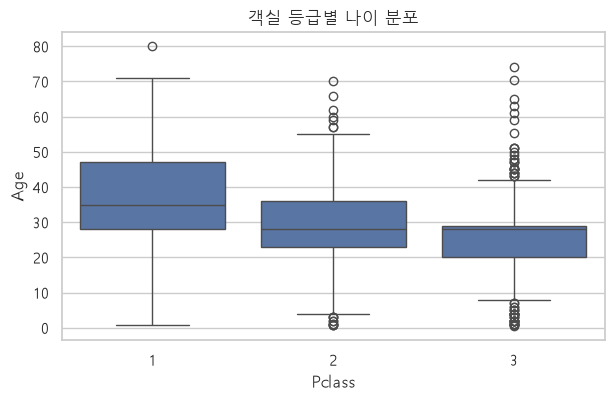

In [63]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=data, x='Pclass', y='Age')
plt.title('객실 등급별 나이 분포')
plt.show()

> 🤔 1등석 승객의 나이 중앙값이 가장 높습니다. 부유한 사람일수록 나이가 많았던 거죠.

### 5-4. 상관관계 한눈에: `heatmap`
숫자 열끼리 얼마나 **같이 움직이는지**(상관계수)를 색으로 보여줍니다.
- +1에 가까울수록: 하나가 크면 다른 것도 큼
- -1에 가까울수록: 하나가 크면 다른 것은 작음
- 0 근처: 관계 없음

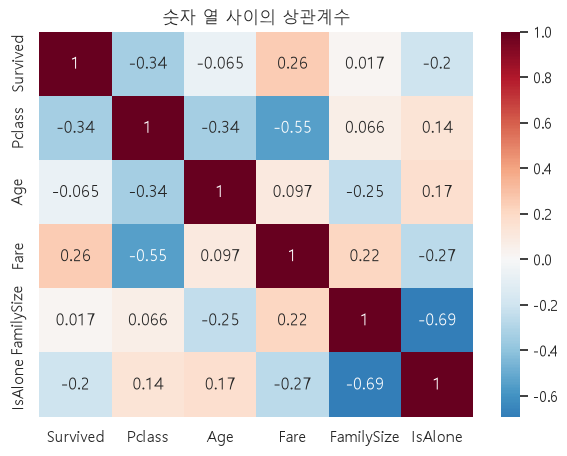

In [64]:
num_cols = ['Survived', 'Pclass', 'Age', 'Fare', 'FamilySize', 'IsAlone']
corr = data[num_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap='RdBu_r', center=0)    # annot=True: 숫자 표시
plt.title('숫자 열 사이의 상관계수')
plt.show()

> 🤔 `Survived` 행을 보세요. `Pclass`와 -0.34 (등급 숫자가 클수록 = 낮은 등급일수록 생존↓), `Fare`와 +0.26 (요금 높을수록 생존↑).
> 상관계수는 **"관계가 있다"**까지만 말해줍니다. "요금을 올리면 생존율이 오른다"는 뜻이 아닙니다.

### ✏️ 실습 5-A. 탑승 항구별 사망/생존 인원

`countplot`으로 x = `Embarked`, 색 구분 = `Survived`인 그래프를 그리세요.

<details>
<summary>💡 힌트 (클릭해서 펼치기)</summary>

5-1의 두 번째 코드에서 `'Pclass'`를 `'Embarked'`로 바꾸세요.

</details>

In [65]:
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x='____', hue='____')
plt.title('탑승 항구별 사망/생존 인원')
plt.show()

ValueError: Could not interpret value `____` for `x`. An entry with this name does not appear in `data`.

<Figure size 600x400 with 0 Axes>

### ✏️ 실습 5-B. 객실 등급별 요금, 생존 여부로 나누어 보기

`boxplot`으로 x = `Pclass`, y = `Fare`, `hue='Survived'`인 그래프를 그리세요. 512달러 때문에 보기 어려우면 `plt.ylim(0, 200)`으로 y축을 자르세요.

<details>
<summary>💡 힌트 (클릭해서 펼치기)</summary>

5-3 코드에서 `y='Age'`를 `y='Fare'`로 바꾸고 `hue='Survived'`와 `plt.ylim(0, 200)`을 추가하세요.

</details>

In [ ]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=data, x='____', y='____', hue='____')
plt.ylim(0, 200)
plt.title('객실 등급 × 생존 여부별 요금')
plt.show()

### ✏️ 실습 5-C. 호칭별 생존율 막대

`barplot`으로 x = `Title`, y = `Survived`인 그래프를 그리세요.

<details>
<summary>💡 힌트 (클릭해서 펼치기)</summary>

5-2 코드에서 `x='Pclass'`를 `x='Title'`로 바꾸고 `hue`는 빼세요.

</details>

In [ ]:
plt.figure(figsize=(7, 4))
sns.barplot(data=data, x='____', y='____')
plt.title('호칭별 생존율')
plt.ylabel('생존율')
plt.show()

---
## 6. 미니 프로젝트 — 직접 결론 내리기 & AI 답변 검증 (30분)

지금까지 배운 것으로 **질문 하나**에 스스로 답해봅니다. 아래 셋 중 **하나**를 고르세요.

| 번호 | 질문 | 쓸 열 |
|---|---|---|
| Q1 | "여성과 아이 먼저"는 정말 지켜졌을까? **3등석에서도?** | `Sex`, `IsChild`, `Pclass` |
| Q2 | 셰르부르(C)에서 탄 사람이 많이 산 이유는? 항구 때문일까, **다른 이유**가 있을까? | `Embarked`, `Pclass` |
| Q3 | 가족과 함께 탄 사람이 많이 살았다. 가족 수가 **많을수록** 좋을까? | `FamilySize` |

### 6-1. 수행 절차 — 아래 셀을 순서대로 채우세요
1. **숫자 표** — `groupby` 또는 `pivot_table`로 핵심 표 1개
2. **그래프** — 그 표를 보여주는 그래프 1개 (`barplot` 추천)
3. **"다른 이유는 없을까?"** — 한 번 더 파고들기. 예) Q2라면 항구별로 1등석 비율이 다른지 `crosstab`으로 확인
4. **결론 3줄** — 맨 아래 글 셀에 작성

Q "여성과 아이 먼저"는 정말 지켜졌을까? "3등석에서도?"

In [66]:
# ── 1. 숫자 표 ─────────────────────────────────
# 예시(Q1): pd.pivot_table(data, index='Pclass', columns='Sex', values='Survived', aggfunc='mean').round(2)
# 예시(Q2): data.groupby('Embarked')['Survived'].agg(['mean', 'count'])
# 예시(Q3): data.groupby('FamilySize')['Survived'].agg(['mean', 'count'])


Q1 = pd.pivot_table(data, index='Pclass', columns='IsChild', values='Survived', aggfunc='mean').round(2)
Q2 = pd.pivot_table(data, index='Pclass', columns='Sex', values='Survived', aggfunc='mean').round(2)


display(Q1)
display(Q2)


IsChild,0,1
Pclass,,
1,0.63,0.75
2,0.42,1.00
3,0.22,0.42


Sex,female,male
Pclass,,
1,0.97,0.37
2,0.92,0.16
3,0.50,0.14


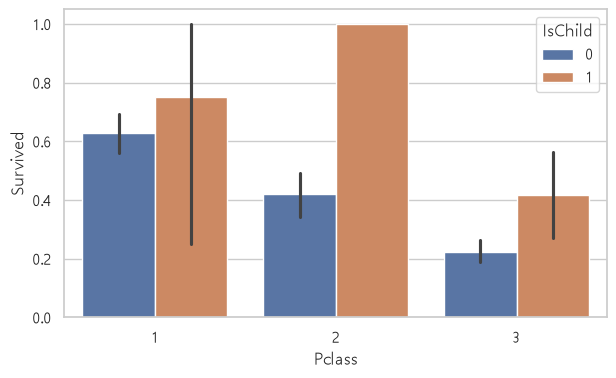

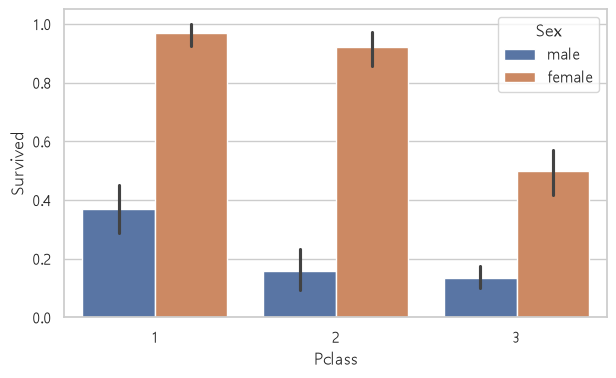

In [68]:
# ── 2. 그래프 ──────────────────────────────────
# 예시: plt.figure(figsize=(7, 4)); sns.barplot(data=data, x='____', y='Survived', hue='____'); plt.show()

plt.figure(figsize=(7, 4)); sns.barplot(data=data, x='Pclass', y='Survived', hue='IsChild'); plt.show()
plt.figure(figsize=(7, 4)); sns.barplot(data=data, x='Pclass', y='Survived', hue='Sex', hue_order=['male', 'female']); plt.show()


In [ ]:
# ── 3. 다른 이유는 없을까? ─────────────────────
# 예시(Q1): 3등석만 골라서(data[data['Pclass']==3]) 어린이 생존율 다시 보기
# 예시(Q2): pd.crosstab(data['Embarked'], data['Pclass'], normalize='index').round(2)
# 예시(Q3): 가족 수가 5명 이상인 사람은 몇 명인지 count 확인

# 생존율만 봤을때는 알 수 없으므로, 인원수를 파악한다.
display(pd.crosstab(data['Pclass'], data['IsChild']))
display(pd.crosstab(data['Pclass'], data['Sex']))

IsChild,0,1
Pclass,,
1,212,4
2,167,17
3,443,48


Sex,female,male
Pclass,,
1,94,122
2,76,108
3,144,347


### 📝 결론 (여기에 직접 작성하세요)

1. **발견한 것**: 모든 등급에서 여성과 아이의 생존율이 남성·어른보다 높아서 "여성과 아이 먼저"는 3등석에서도 지켜졌다. 하지만 3등석 여성과 아이의 생존율은 1·2등석보다 훨씬 낮았다.
2. **근거가 되는 숫자**: 여성 생존율: 1등석 약 0.97, 2등석 약 0.92, 3등석 약 0.50 (남성은 0.37, 0.16, 0.14)
3등석 아이 약 0.42, 3등석 어른 약 0.22
3. **주의할 점 / 확실하지 않은 것**: 1등석 아이는 인원이 적어서 오차 막대가 길다. 그래서 1등석 아이 생존율은 믿기 어렵다. 성별 표의 여성에는 아이도 섞여 있다. 3등석 생존율이 낮은 이유(객실 위치, 구명보트 접근성 등)는 이 데이터만으로는 확인할 수 없다.

### 6-2. 🔍 AI 답변 검증 — AI가 한 말을 데이터로 확인하기

ChatGPT, Claude, Gemini 같은 AI에게 아래 질문을 **그대로 복사해서** 물어보세요.

> "Kaggle 타이타닉 train.csv(891명) 데이터에서 여성 생존율, 남성 생존율, 1등석 생존율, 3등석 생존율, 13세 미만 어린이 생존율, 셰르부르(C) 탑승객 생존율을 각각 퍼센트로 알려줘."

AI 답을 아래 표의 가운데 열에 적고, 다음 셀을 실행해서 **직접 계산한 값**과 비교하세요.

| 항목 | AI가 말한 값 | 내가 계산한 값 | 일치? |
|---|---|---|---|
| 여성 생존율 |74.2%|74.2%|o|
| 남성 생존율 |18.89%|18.9%|o|
| 1등석 생존율 |62.96%|63.0%|o|
| 3등석 생존율 |24.24%|24.2%|o|
| 13세 미만 어린이 생존율 |57.97%|58.0%|o|
| 셰르부르(C) 탑승객 생존율 |55.36%|55.4%|o|

In [71]:
# 내가 직접 계산한 값
print('여성 생존율      :', round(data[data['Sex'] == 'female']['Survived'].mean() * 100, 1), '%')
print('남성 생존율      :', round(data[data['Sex'] == 'male']['Survived'].mean() * 100, 1), '%')
print('1등석 생존율     :', round(data[data['Pclass'] == 1]['Survived'].mean() * 100, 1), '%')
print('3등석 생존율     :', round(data[data['Pclass'] == 3]['Survived'].mean() * 100, 1), '%')
print('어린이 생존율    :', round(data[data['Age'] < 13]['Survived'].mean() * 100, 1), '%  (빈 칸을 28세로 채운 뒤)')
print('어린이 생존율    :', round(df[df['Age'] < 13]['Survived'].mean() * 100, 1), '%  (원본, 빈 칸 제외)')
print('C 탑승객 생존율  :', round(data[data['Embarked'] == 'C']['Survived'].mean() * 100, 1), '%')

여성 생존율      : 74.2 %
남성 생존율      : 18.9 %
1등석 생존율     : 63.0 %
3등석 생존율     : 24.2 %
어린이 생존율    : 58.0 %  (빈 칸을 28세로 채운 뒤)
어린이 생존율    : 58.0 %  (원본, 빈 칸 제외)
C 탑승객 생존율  : 55.4 %


**검증한 뒤 생각해 볼 것**
- AI가 틀린 숫자가 있었나요? 유명한 숫자(여성 생존율)는 맞고, 세부 숫자(어린이, C 항구)는 틀리지 않았나요?
- AI가 "약 ~%"처럼 얼버무린 항목이 있었나요? 왜 그랬을까요?
- 어린이 생존율은 **빈 칸을 어떻게 처리했느냐**에 따라 달라질 수 있습니다. (오늘은 중앙값 28세로 채워서 원본과 같지만, 평균이나 0으로 채우면 달라집니다.) AI가 이 점을 말해줬나요?
- 앞으로 AI가 숫자를 말하면 어떻게 할 건가요? **"출처가 뭐야?" / "어떻게 계산했어?"**라고 되묻는 습관을 들여보세요.

> 💬 AI는 그럴듯한 문장을 만드는 데 뛰어나지만, 데이터를 실제로 열어보지 않고 **기억에 의존해** 숫자를 말할 때가 많습니다. 오늘 배운 10줄짜리 코드가 AI 답변을 검증하는 가장 확실한 도구입니다.

---
## 7. 정리

### 7-1. 오늘 배운 명령어 (이것만 기억하세요)

| 하고 싶은 일 | 코드 |
|---|---|
| 파일 읽기 | `pd.read_csv('파일.csv')` |
| 처음 몇 줄 | `df.head()` |
| 크기 | `df.shape` |
| 요약 | `df.info()`, `df.describe()` |
| 열 하나 | `df['열']` |
| 열 여러 개 | `df[['열1', '열2']]` |
| 값 세기 | `df['열'].value_counts()` |
| 조건으로 행 고르기 | `df[df['열'] == 값]` |
| 조건 두 개 | `df[(조건1) & (조건2)]` |
| 빈 칸 세기 | `df.isnull().sum()` |
| 빈 칸 채우기 | `df['열'].fillna(값)` |
| 새 열 | `df['새열'] = 계산식` |
| 구간 나누기 | `pd.cut(df['열'], bins=[...], labels=[...])` |
| 그룹별 통계 | `df.groupby('기준')['열'].mean()` |
| 표 모양 | `pd.pivot_table(df, index=, columns=, values=, aggfunc=)` |
| 막대 / 히스토그램 | `plt.bar()`, `plt.hist()` |
| seaborn | `sns.countplot()`, `sns.barplot()`, `sns.boxplot()` + `hue=` |

### 7-2. 자주 하는 실수

| 실수 | 나타나는 오류 / 증상 | 고치는 법 |
|---|---|---|
| 열 이름 따옴표 빠뜨림 `df[Age]` | `NameError: name 'Age' is not defined` | `df['Age']` |
| 열 이름 오타 `df['age']` | `KeyError: 'age'` | 대소문자 확인. `df.columns`로 열 이름 목록 보기 |
| 조건에 `and` 사용 | `ValueError: The truth value of a Series is ambiguous` | `&`로 바꾸고 각 조건에 괄호 |
| `shape()` 처럼 괄호 붙임 | `TypeError: 'tuple' object is not callable` | `shape`는 괄호 없음 |
| 열 여러 개에 대괄호 한 겹 `df['Name', 'Age']` | `KeyError` | 대괄호 두 겹 `df[['Name', 'Age']]` |
| 빈 칸 무시하고 분석 | 오류는 없지만 결과가 왜곡됨 | 먼저 `isnull().sum()` |
| 개수와 비율 혼동 | "20대가 제일 많이 죽었다" (20대가 제일 많이 탔을 뿐) | 생존율(`mean`)로 비교 |
| 상관 = 원인 | "요금 올리면 생존율 오른다" | "관련이 있다"로만 표현 |

### 7-3. 다음에 배울 것
- `loc`, `iloc`로 행·열 정밀하게 고르기
- `merge`로 표 두 개 합치기
- 호칭별 중앙값처럼 **그룹별로 다르게** 빈 칸 채우기 (`transform`)
- 머신러닝으로 생존 예측하기 (`scikit-learn`)

> 오늘 가장 중요한 것 하나: **숫자를 보기 전에 데이터를 의심하고(빈 칸은? 몇 명?), 숫자를 본 뒤에는 "다른 이유는 없을까?"를 묻는 것.** 도구는 바뀌어도 이 습관은 남습니다.